# 4. Publication figures — `be_scan.figure_plot`

`be_scan.figure_plot` is the layer for figures that go into a paper. It
differs from `be_scan.plot` in two ways:

1. **Options come as frozen dataclasses** rather than loose keyword
   arguments, so a style can be defined once and reused across every panel
   of a figure.
2. **Every function has an interactive twin.** The twin takes the same
   arguments and is styled from the same option objects, so the two
   renderings agree. It writes its `.html` beside the static file.

In [1]:
%matplotlib inline
import plotly.io as pio
# load plotly.js from a CDN in the rendered docs rather than
# embedding ~3 MB of it in every notebook output
pio.renderers.default = "notebook_connected"

import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import be_scan.figure_plot as fp
from be_scan.figure_plot import (
    AxisLabelOpts, DomainOpts, LegendOpts, NegCtrlOpts,
    OutputOpts, ScatterStyleOpts, BoxStyleOpts,
)

scores = pd.read_csv("data/FOXA1_ABE_scores.csv")
coding = scores[scores["AtoG_muttype"].isin(
    ["Missense", "Nonsense", "Silent"])].copy()
print(coding.shape)

(580, 69)


## The option objects

| dataclass | controls |
|---|---|
| `AxisLabelOpts` | title, labels, limits, ticks, x window |
| `ScatterStyleOpts` / `BoxStyleOpts` / ... | colours, markers, per-layer keywords |
| `DomainOpts` | shaded protein domains |
| `LegendOpts` | placement, columns, separate legend file |
| `NegCtrlOpts` | normalization and +/- SD guide lines |
| `OutputOpts` | figure size, dpi, format, whether to save or show |

They are frozen, so build a variant with `dataclasses.replace` rather than
mutating one.

In [2]:
from dataclasses import replace

AXIS = AxisLabelOpts(
    xlabel = "FOXA1 residue", ylabel = "log2 fold change",
    xlim = (1, 473), xticks = [1, 100, 200, 300, 400, 473],
)
STYLE = ScatterStyleOpts(
    hue_col = "AtoG_muttype",
    color_map = {"Missense": "#fb8072", "Nonsense": "#80b1d3",
                 "Silent": "#d9d9d9"},
    transparency_threshold = 1.0,
)
DOMAIN = DomainOpts(dom_setting = [{"start": 168, "end": 258}])
OUT = OutputOpts(figsize = (5.0, 2.2), save = False, show = True,
                 out_type = "svg", dpi = 600, transparent = True)

# a variant for a taller panel
TALL = replace(OUT, figsize = (5.0, 3.2))

## A static figure and its interactive twin

The only difference between these two calls is the function name.

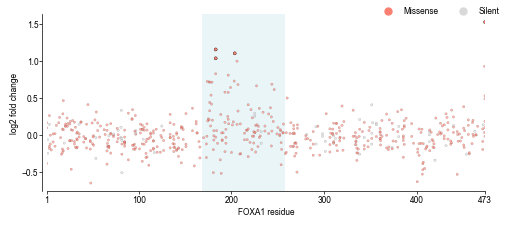

In [3]:
fig, axes = fp.scatterplot_figure(
    coding, ["sorted_top-unsorted"], "AtoG_pos",
    axis = AXIS, style = STYLE, domain = DOMAIN,
    legend = LegendOpts(loc = "upper right", ncol = 3, path = None),
    output = OUT,
)

In [4]:
fp.interactive_scatterplot_figure(
    coding, ["sorted_top-unsorted"], "AtoG_pos",
    axis = AXIS, style = STYLE, domain = DOMAIN,
    legend = LegendOpts(loc = "upper right", ncol = 3, path = None),
    output = OUT,
    hover_cols = ["sgRNA_ID", "AtoG_mutations", "AtoG_muttype"],
)

### Why `scale`

`OutputOpts.figsize` is in inches for print — typically 4 x 2.2 at 6 pt type.
That is illegible in a browser, so the interactive functions take `scale`,
which multiplies pixel size and font size by the same factor. Proportions are
preserved exactly; `scale=1.0` reproduces the print geometry.

In [5]:
fp.interactive_scatterplot_figure(
    coding, ["sorted_top-unsorted"], "AtoG_pos",
    axis = AXIS, style = STYLE, output = OUT,
    scale = 3.0,          # same figure, larger on screen
)

### Saving both

Give `OutputOpts.path` a stem. The static figure takes `out_type`, the
interactive one takes `.html`, and they land side by side.

In [6]:
SAVE = replace(OUT, save = True, show = False, path = "output/foxa1_scatter")

fp.scatterplot_figure(coding, ["sorted_top-unsorted"], "AtoG_pos",
                      axis = AXIS, style = STYLE, output = SAVE,
                      legend = LegendOpts(path = "output/foxa1_legend"))
fp.interactive_scatterplot_figure(coding, ["sorted_top-unsorted"], "AtoG_pos",
                                  axis = AXIS, style = STYLE, output = SAVE)

import os
sorted(os.listdir("output"))

['foxa1_legend.svg', 'foxa1_scatter.html', 'foxa1_scatter.svg']

## Boxplot pair

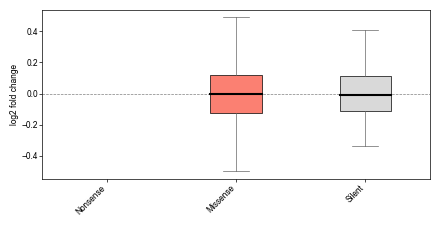

(<Figure size 500x220 with 1 Axes>, <AxesSubplot:ylabel='log2 fold change'>)

In [7]:
BOX_AXIS = replace(AXIS, xlabel = "", ylabel = "log2 fold change",
                   xlim = None, xticks = None)
PALETTE = {"Missense": "#fb8072", "Nonsense": "#80b1d3", "Silent": "#d9d9d9"}

fp.boxplot_figure(coding, "AtoG_muttype", "sorted_top-unsorted",
                  palette = PALETTE,
                  lab_order = ["Nonsense", "Missense", "Silent"],
                  axis = BOX_AXIS, output = OUT)

In [8]:
fp.interactive_boxplot_figure(coding, "AtoG_muttype", "sorted_top-unsorted",
                              palette = PALETTE,
                              lab_order = ["Nonsense", "Missense", "Silent"],
                              axis = BOX_AXIS, output = OUT)

## Correlation pair

`correlation_scatterplot_figure` draws a line of best fit, prints Pearson r,
and outlines a chosen set of categories so they stay visible against the bulk.

Best fit line: y = -0.1864x + -0.0030
Pearson r = -0.1874, p = 5.5547e-06


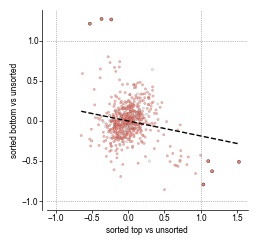

In [9]:
CORR_AXIS = AxisLabelOpts(xlabel = "sorted top vs unsorted",
                          ylabel = "sorted bottom vs unsorted")

fp.correlation_scatterplot_figure(
    coding, "sorted_top-unsorted", "sorted_bottom-unsorted",
    legend_order = ["Missense", "Nonsense", "Silent"],
    hue_col = "AtoG_muttype", palette = PALETTE,
    highlight_col = "AtoG_muttype", highlight_categories = ["Nonsense"],
    axis = CORR_AXIS, style = STYLE,
    output = replace(OUT, figsize = (2.6, 2.6)),
)

In [10]:
fp.interactive_correlation_scatterplot_figure(
    coding, "sorted_top-unsorted", "sorted_bottom-unsorted",
    legend_order = ["Missense", "Nonsense", "Silent"],
    hue_col = "AtoG_muttype", palette = PALETTE,
    highlight_col = "AtoG_muttype", highlight_categories = ["Nonsense"],
    axis = CORR_AXIS, style = STYLE,
    output = replace(OUT, figsize = (2.6, 2.6)),
    hover_cols = ["sgRNA_ID", "AtoG_mutations"],
)

## The full set of pairs

| static | interactive |
|---|---|
| `scatterplot_figure` | `interactive_scatterplot_figure` |
| `correlation_scatterplot_figure` | `interactive_correlation_scatterplot_figure` |
| `boxplot_figure` | `interactive_boxplot_figure` |
| `jitterbox_kdeplot_figure` | `interactive_jitterbox_kdeplot_figure` |
| `lollipop_figure` | `interactive_lollipop_figure` |
| `lollipop_split_figure` | `interactive_lollipop_split_figure` |
| `kmeans_clustered_heatmap` | `interactive_kmeans_clustered_heatmap` |
| `loess_figure` | `interactive_loess_figure` |
| `pwes_histogram` | `interactive_pwes_histogram` |
| `pwes_boxplots` | `interactive_pwes_boxplots` |
| `pwes_scatterplots` | `interactive_pwes_scatterplots` |
| `pwes_heatmap` | `interactive_pwes_heatmap` |
| `pwes_clustermap` | `interactive_pwes_clustermap` |
| `pwes_heatmap_colorbar` | `interactive_pwes_heatmap_colorbar` |

## How the two are kept consistent

Not by copying numbers. `figure_interactive_style` reads the live matplotlib
rcParams the static figures use, so restyling one restyles the other, and it
pulls marker and line styling out of the same dataclass fields.

In [11]:
from be_scan.figure_plot import figure_interactive_style as ivs
import matplotlib

print("font size   :", ivs.BASE_FONT, "==", matplotlib.rcParams["font.size"])
print("axes width  :", ivs.BASE_AXES_LW, "==", matplotlib.rcParams["axes.linewidth"])
print("tick width  :", ivs.BASE_TICK_W, "==", matplotlib.rcParams["xtick.major.width"])

# matplotlib's `s` is an area, plotly's size is a diameter
print("\nmarker s=25 ->", ivs.marker_size(25, scale=1.0), "px diameter")
# matplotlib colour shorthands are translated for plotly
print("colour 'k'  ->", ivs.to_css("k"))

font size   : 6.0 == 6.0
axes width  : 0.5 == 0.5
tick width  : 0.5 == 0.5

marker s=25 -> 5.0 px diameter
colour 'k'  -> #000000


### File size

plotly.js is embedded by default, so each `.html` is self-contained (~3.7 MB)
and opens with no network — it survives being emailed to a collaborator. If
you are writing many figures and would rather have small files:

```python
from be_scan.figure_plot import figure_interactive_style as ivs
ivs.INCLUDE_PLOTLYJS = "cdn"      # ~40 KB per file, needs a connection
```

## 3D clustering — PWES

`pwes_clustering` weights every pair of guides by how close their residues
are in a structure, then clusters the result. It needs a `.pdb`.

```python
from be_scan.figure_plot import pwes_clustering, pwes_histogram, pwes_heatmap

df_gauss, df_sorted, df_unsorted, df_clus, aas_dict, link = pwes_clustering(
    df_scores  = coding,
    x_col      = "AtoG_pos",
    scores_col = "sorted_top-unsorted",
    pdb_file   = "AF_FOXA1.pdb",
    gauss_std  = 16,     # spatial bandwidth, angstroms
    dend_t     = 14,     # dendrogram cut height
    out_prefix = "foxa1", out_dir = "output",
)

colors = ["#fb8072", "#80b1d3", "#fdb462", "#b3de69", "#bebada"]
pwes_histogram(df_clus, colors, output = OUT)
pwes_heatmap(df_sorted, output = OUT)
```

The cluster column is named `cl_new`. `out_dir` is joined as a path, so it no
longer matters whether you include a trailing separator.